# 07 · Acuerdo entre anotadores del Pitt Image Ads Dataset

El sitio de anuncios atípicos (notebook 06) muestra un solo conjunto de etiquetas por imagen. Detrás de cada imagen hay **3 o 5 trabajadores de Amazon Mechanical Turk** que respondieron por separado. Este notebook descarga esos **votos individuales** desde la publicación oficial del dataset y mide cuánto coinciden.

**Fuente:** `annotations_images.zip` en <https://people.cs.pitt.edu/~kovashka/ads/> (Hussain et al., CVPR 2017).
- `Topics.json`: cada anotador elige **un** tema (38 opciones, más "Other" con texto libre).
- `Sentiments.json`: cada anotador elige **uno o más** sentimientos (30 opciones).

**Poblaciones analizadas**
- **Subconjunto atípico:** las 2.404 imágenes del sitio del notebook 06. Es el foco del análisis.
- **Dataset completo:** como referencia, con 64.340 imágenes con tema y 30.340 con sentimientos.

**Medidas**

| Medida | Qué compara | Uso aquí |
|---|---|---|
| κ de Fleiss | proporción de pares de anotadores que coinciden, corregida por el azar | temas; sentimientos como conjunto exacto y por sentimiento (sí/no) |
| α de Krippendorff | desacuerdo observado frente al esperado; admite distinto número de anotadores y distancias parciales | temas (nominal); sentimientos con distancia nominal, Jaccard y MASI |

En los sentimientos, cada anotador marca un **conjunto**: con distancia nominal, {alerta, creativo} frente a {creativo} cuenta como desacuerdo total. Jaccard y MASI dan **crédito parcial** cuando los conjuntos se solapan, como en el notebook 05.

**Escalas de interpretación**
- κ (Landis y Koch, 1977): < 0 pobre · 0–0,20 leve · 0,21–0,40 aceptable · 0,41–0,60 moderado · 0,61–0,80 sustancial · > 0,80 casi perfecto.
- α (Krippendorff, 2004): ≥ 0,80 confiable · 0,667–0,80 solo conclusiones tentativas · < 0,667 no confiable.

### ⏱ Tiempo estimado en Colab T4

No usa GPU. Los votos (`pitt/votos/`) ya vienen en el repositorio, así que no hay descarga grande. El costo está en los intervalos *bootstrap* de κ por sentimiento (30 sentimientos sobre ~30.000 anuncios). Estimado, sin medir: **5–20 min** en total.

*Supuestos: Colab gratis con T4 y 2 CPU. **Medido** = cronometrado (salidas guardadas o prueba en una máquina de 2 CPU); **estimado** = calculado con el rendimiento publicado de la T4. Con Colab Pro (8 CPU) las partes limitadas por CPU bajan. Las sesiones gratis se cortan a las ~12 h o tras ~90 min sin interacción; lo que dice "reanudable" retoma donde quedó al volver a ejecutar.*

## 1. Configuración

In [1]:
import io
import json
import os
import urllib.request
import zipfile
from collections import Counter
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse

pd.set_option('display.float_format', '{:.3f}'.format)

# En Colab, datos y resultados quedan en Google Drive (misma carpeta base que 01, 04 y 06)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive/publicity_analysis'
except ImportError:
    DRIVE_ROOT = '.'

PITT_DIR = os.path.join(DRIVE_ROOT, 'pitt')
VOTOS_DIR = os.path.join(PITT_DIR, 'votos')
OUT = os.path.join(DRIVE_ROOT, 'resultados', 'pitt')
os.makedirs(VOTOS_DIR, exist_ok=True)
os.makedirs(OUT, exist_ok=True)

N_BOOT = 300   # réplicas bootstrap para los IC95%
SEED = 0
print('Votos en:', os.path.abspath(VOTOS_DIR))
print('Resultados en:', os.path.abspath(OUT))

Votos en: /Users/miguelcarrascoudp/Documents/GitHub/publicity_analysis/pitt/votos
Resultados en: /Users/miguelcarrascoudp/Documents/GitHub/publicity_analysis/resultados/pitt


## 2. Descarga de los votos individuales y del subconjunto atípico

In [2]:
UA = {'User-Agent': 'Mozilla/5.0 (research dataset downloader)'}
URL_ZIP = 'https://people.cs.pitt.edu/~kovashka/ads/annotations_images.zip'
URL_CTS = 'https://people.cs.pitt.edu/~nhonarvar/data_analysis/category_topic_sentiment.json'


def fetch(url):
    with urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=60) as r:
        return r.read()


img_dir = os.path.join(VOTOS_DIR, 'image')
if not os.path.exists(os.path.join(img_dir, 'Sentiments.json')):
    print('Descargando', URL_ZIP)
    with zipfile.ZipFile(io.BytesIO(fetch(URL_ZIP))) as z:
        z.extractall(VOTOS_DIR)

topics_raw = json.load(open(os.path.join(img_dir, 'Topics.json')))
sents_raw = json.load(open(os.path.join(img_dir, 'Sentiments.json')))

# Nombres de las clases (los .txt vienen en codificaciones distintas)
import re
def parse_list(path, enc):
    out = {}
    for line in open(path, encoding=enc):
        m = re.match(r'\s*(\d+)\.?\s+"([^"]+)"(?:.*ABBREVIATION:\s*"([^"]+)")?', line)
        if m:   # abreviatura si existe; si no (p. ej. 39 "Unclear"), el nombre en minúsculas
            out[m.group(1)] = m.group(3) or m.group(2).lower()
    return out

TOPIC_NAMES = parse_list(os.path.join(img_dir, 'Topics_List.txt'), 'utf-16')
SENT_NAMES = parse_list(os.path.join(img_dir, 'Sentiments_List.txt'), 'latin-1')
print(f'{len(TOPIC_NAMES)} temas, {len(SENT_NAMES)} sentimientos')

# Subconjunto atípico: se reutiliza el JSON del notebook 06 si existe
cts_path = os.path.join(PITT_DIR, 'raw', 'category_topic_sentiment.json')
if os.path.exists(cts_path):
    cts = json.load(open(cts_path))
else:
    cts = json.loads(fetch(URL_CTS))


def key_of(image_id):
    # '110991.jpg' → '1/110991.jpg' (misma regla que id2url() del sitio)
    stem = image_id.split('.')[0]
    return ('10' if int(stem) >= 170000 else stem[-1]) + '/' + image_id


site = {}   # clave → {'category': set, 'topic': set, 'sentiment': set} según el sitio
for cat, temas in cts.items():
    for tema, ss in temas.items():
        for s, ids in ss.items():
            for i in ids:
                d = site.setdefault(key_of(i), {'category': set(), 'topic': set(), 'sentiment': set()})
                d['category'].add(cat); d['topic'].add(tema); d['sentiment'].add(s)
ATIP = sorted(site)
print(f'Subconjunto atípico: {len(ATIP)} imágenes · con votos de tema: {sum(k in topics_raw for k in ATIP)} · '
      f'con votos de sentimiento: {sum(k in sents_raw for k in ATIP)}')

39 temas, 30 sentimientos
Subconjunto atípico: 2404 imágenes · con votos de tema: 2404 · con votos de sentimiento: 2404


## 3. Preparación de los votos

- **Tema:** cada voto es un código. Las respuestas "Other" (texto libre, ~1 % de los votos) se agrupan en una sola categoría `other`, porque el texto no es comparable entre anotadores.
- **Sentimiento:** cada voto es el **conjunto** de sentimientos que marcó el anotador.

In [3]:
def topic_label(v):
    v = str(v).strip()
    return TOPIC_NAMES.get(v, 'other') if v.isdigit() else 'other'


TOPICS = {k: [topic_label(v) for v in vs] for k, vs in topics_raw.items()}
SENTS = {k: [frozenset(SENT_NAMES.get(x, x) for x in v) for v in vs] for k, vs in sents_raw.items()}

resumen = []
for nombre, X, ids in [('Tema · completo', TOPICS, list(TOPICS)), ('Tema · atípico', TOPICS, ATIP),
                       ('Sentimiento · completo', SENTS, list(SENTS)), ('Sentimiento · atípico', SENTS, ATIP)]:
    n = Counter(len(X[k]) for k in ids)
    resumen.append({'conjunto': nombre, 'imágenes': len(ids), '3 anotadores': n[3], '5 anotadores': n[5],
                    'votos': sum(n_ * c for n_, c in n.items())})
display(pd.DataFrame(resumen).set_index('conjunto'))

otros = sum(v == 'other' for vs in TOPICS.values() for v in vs) / sum(len(vs) for vs in TOPICS.values())
print(f'Votos de tema "Other": {otros:.1%}')
n_sel = pd.Series([len(v) for k in ATIP for v in SENTS[k]])
print('Sentimientos marcados por anotador (atípico):', n_sel.value_counts().sort_index().head(6).to_dict(),
      f'· media {n_sel.mean():.2f}')

,imágenes,3 anotadores,5 anotadores,votos
conjunto,,,,
Tema · completo,64340,58680,5660,204340
Tema · atípico,2404,1472,932,9076
Sentimiento · completo,30340,24680,5660,102340
Sentimiento · atípico,2404,1472,932,9076


Votos de tema "Other": 1.2%
Sentimientos marcados por anotador (atípico): {1: 6673, 2: 1438, 3: 601, 4: 213, 5: 80, 6: 37} · media 1.44


### 3b. ¿Qué muestra el sitio?

Se compara la etiqueta que muestra el sitio con los votos: ¿es la **unión** de lo que marcaron los anotadores, o la **mayoría**?

In [4]:
def majority(vals, thr=0.5):
    c = Counter(vals); n = len(vals)
    return {v for v, k in c.items() if k / n > thr}

rows = []
for k in ATIP:
    t_votes = TOPICS[k]; s_votes = [x for v in SENTS[k] for x in v]
    rows.append({
        'tema = unión': site[k]['topic'] == set(t_votes) - {'other'},
        'tema = mayoría': site[k]['topic'] == majority(t_votes) - {'other'},
        'sent. = unión': site[k]['sentiment'] == set(s_votes),
        'sent. ⊆ unión': site[k]['sentiment'] <= set(s_votes),
    })
pd.DataFrame(rows).mean().rename('proporción de imágenes').to_frame()

,proporción de imágenes
tema = unión,0.919
tema = mayoría,0.648
sent. = unión,1.000
sent. ⊆ unión,1.000


## 4. Funciones de acuerdo

**κ de Fleiss** (versión que admite distinto número de anotadores por imagen):

$$P_i = \frac{\sum_k n_{ik}(n_{ik}-1)}{n_i(n_i-1)},\qquad \bar P = \frac1N\sum_i P_i,\qquad P_e=\sum_k p_k^2,\qquad \kappa=\frac{\bar P-P_e}{1-P_e}$$

donde $p_k$ es la proporción de todos los votos que eligieron la categoría *k*.

**α de Krippendorff** a partir de la matriz de coincidencias, con una distancia $d$ entre respuestas:

$$\alpha = 1-\frac{D_o}{D_e},\qquad D_o=\frac1n\sum_i\frac{\sum_{a\ne b\in i} d(a,b)}{m_i-1},\qquad D_e=\frac{\sum_{c,k} n_c n_k\, d(c,k)}{n(n-1)}$$

- **nominal:** $d=0$ si son iguales, 1 si no.
- **Jaccard:** $d = 1 - |A\cap B|/|A\cup B|$.
- **MASI** (Passonneau, 2006): $d = 1 - J\cdot M$, con $M=1$ si son iguales, 2/3 si uno contiene al otro, 1/3 si solo se solapan y 0 si son disjuntos.

Los IC95% se obtienen con bootstrap sobre imágenes. Las distancias entre conjuntos se calculan de forma vectorizada (en el dataset completo hay ~5.000 conjuntos distintos).

In [5]:
def encode(units):
    # units: lista de listas de respuestas → índices por unidad y lista de valores distintos
    values = sorted({v for u in units for v in u}, key=lambda x: (str(type(x)), sorted(x) if isinstance(x, frozenset) else x))
    pos = {v: i for i, v in enumerate(values)}
    return [np.array([pos[v] for v in u]) for u in units], values


def counts_matrix(idx, K):
    rows = np.repeat(np.arange(len(idx)), [len(u) for u in idx])
    return sparse.csr_matrix((np.ones(len(rows)), (rows, np.concatenate(idx))), shape=(len(idx), K))


def set_distances(values, kind):
    if kind == 'nominal':
        return 1.0 - np.eye(len(values))
    items = sorted({x for v in values for x in v})
    p = {x: j for j, x in enumerate(items)}
    B = np.zeros((len(values), len(items)), dtype=np.float32)
    for i, v in enumerate(values):
        B[i, [p[x] for x in v]] = 1
    inter = B @ B.T
    s = B.sum(1)
    union = s[:, None] + s[None, :] - inter
    J = np.where(union > 0, inter / np.maximum(union, 1), 1.0)
    if kind == 'jaccard':
        return (1 - J).astype(np.float64)
    equal = (inter == s[:, None]) & (inter == s[None, :])
    subset = (inter == s[:, None]) | (inter == s[None, :])
    M = np.select([equal, subset, inter > 0], [1.0, 2 / 3, 1 / 3], 0.0)
    return (1 - J * M).astype(np.float64)


def krippendorff(units, kind='nominal', n_boot=N_BOOT, seed=SEED):
    idx, values = encode(units)
    D = set_distances(values, kind)
    m = np.array([len(u) for u in idx], dtype=float)
    # desacuerdo observado de cada unidad: Σ_{a≠b} d / (m−1)
    d_u = np.array([D[np.ix_(u, u)].sum() / (len(u) - 1) for u in idx])
    C = counts_matrix(idx, len(values))

    def alpha(sel):
        n_c = np.asarray(C[sel].sum(0)).ravel()
        n = n_c.sum()
        De = n_c @ D @ n_c / (n * (n - 1))
        return 1 - (d_u[sel].sum() / n) / De

    a = alpha(np.arange(len(idx)))
    g = np.random.default_rng(seed)
    boot = [alpha(g.integers(0, len(idx), len(idx))) for _ in range(n_boot)]
    return a, *np.percentile(boot, [2.5, 97.5])


def fleiss(units, n_boot=N_BOOT, seed=SEED):
    idx, values = encode(units)
    C = counts_matrix(idx, len(values))
    n_i = np.asarray(C.sum(1)).ravel()
    P_i = np.asarray(C.multiply(C).sum(1)).ravel() - n_i
    P_i = P_i / (n_i * (n_i - 1))

    def kappa(sel):
        p = np.asarray(C[sel].sum(0)).ravel(); p = p / p.sum()
        Pe = (p ** 2).sum()
        return (P_i[sel].mean() - Pe) / (1 - Pe), P_i[sel].mean(), Pe

    k, P_bar, Pe = kappa(np.arange(len(idx)))
    g = np.random.default_rng(seed)
    boot = [kappa(g.integers(0, len(idx), len(idx)))[0] for _ in range(n_boot)]
    return k, *np.percentile(boot, [2.5, 97.5]), P_bar, Pe


def landis_koch(k):
    for lim, txt in [(0, 'pobre'), (0.2, 'leve'), (0.4, 'aceptable'), (0.6, 'moderado'), (0.8, 'sustancial')]:
        if k <= lim:
            return txt
    return 'casi perfecto'


def kripp_level(a):
    return 'confiable' if a >= 0.8 else ('tentativo' if a >= 0.667 else 'no confiable')


RESULTS = []
def report(variable, conjunto, medida, est, lo, hi, n_img, extra=None):
    nivel = kripp_level(est) if medida.startswith('α') else landis_koch(est)
    RESULTS.append({'variable': variable, 'conjunto': conjunto, 'medida': medida, 'valor': est,
                    'IC95_inf': lo, 'IC95_sup': hi, 'imágenes': n_img, 'interpretación': nivel, **(extra or {})})
    print(f'{variable:<12} {conjunto:<9} {medida:<22} {est:.3f} [{lo:.3f}, {hi:.3f}]  → {nivel}')

## 5. Tema (una etiqueta por anotador)

Además de κ y α, se calcula el **acuerdo con la mayoría**: la proporción de votos que coinciden con el tema más votado de su imagen. Es lo más parecido al "85 % de acuerdo" que informa el paper, aunque el paper no detalla su cálculo.

In [6]:
topic_pi = {}
for conjunto, ids in [('atípico', ATIP), ('completo', list(TOPICS))]:
    units = [TOPICS[k] for k in ids]
    k, lo, hi, P_bar, Pe = fleiss(units)
    report('tema', conjunto, 'κ Fleiss', k, lo, hi, len(units), {'P_obs': P_bar, 'P_azar': Pe})
    a, lo, hi = krippendorff(units, 'nominal')
    report('tema', conjunto, 'α Krippendorff nominal', a, lo, hi, len(units))
    modal = np.mean([Counter(u).most_common(1)[0][1] / len(u) for u in units])
    unan = np.mean([len(set(u)) == 1 for u in units])
    sin_may = np.mean([Counter(u).most_common(1)[0][1] / len(u) <= 0.5 for u in units])
    print(f'{"":<22} acuerdo con la mayoría {modal:.1%} · unánimes {unan:.1%} · sin mayoría {sin_may:.1%}\n')
    topic_pi[conjunto] = units

# Sensibilidad: imágenes con 3 frente a 5 anotadores (atípico)
for n in (3, 5):
    units = [u for u in topic_pi['atípico'] if len(u) == n]
    k, lo, hi, *_ = fleiss(units, n_boot=100)
    print(f'atípico, {n} anotadores ({len(units)} imágenes): κ = {k:.3f} [{lo:.3f}, {hi:.3f}]')

tema         atípico   κ Fleiss               0.745 [0.733, 0.760]  → sustancial
tema         atípico   α Krippendorff nominal 0.746 [0.733, 0.761]  → tentativo
                       acuerdo con la mayoría 86.2% · unánimes 63.9% · sin mayoría 7.4%

tema         completo  κ Fleiss               0.715 [0.712, 0.718]  → sustancial
tema         completo  α Krippendorff nominal 0.717 [0.714, 0.720]  → tentativo
                       acuerdo con la mayoría 85.2% · unánimes 63.0% · sin mayoría 8.0%

atípico, 3 anotadores (1472 imágenes): κ = 0.743 [0.724, 0.762]
atípico, 5 anotadores (932 imágenes): κ = 0.748 [0.729, 0.766]


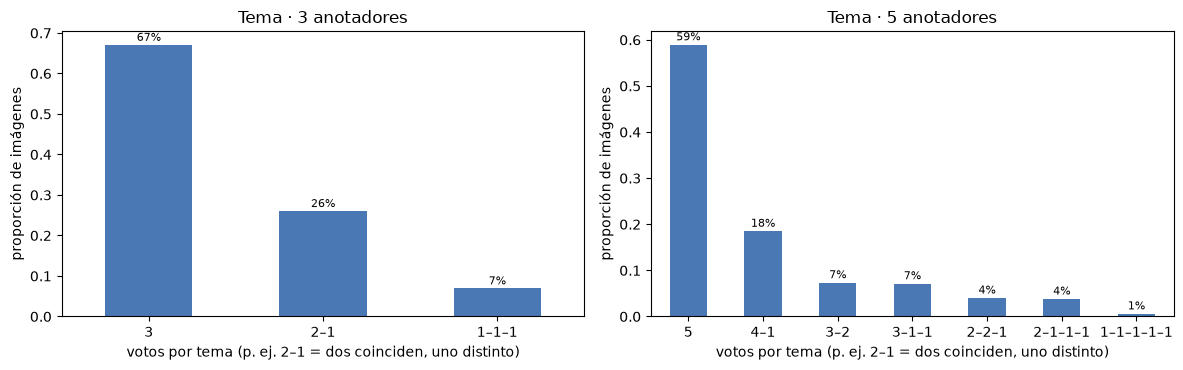

In [7]:
# Distribución del acuerdo por imagen (patrón de votos) en el subconjunto atípico
def pattern(u):
    return '–'.join(str(c) for c in sorted(Counter(u).values(), reverse=True))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, n in zip(axes, (3, 5)):
    s = pd.Series([pattern(u) for u in topic_pi['atípico'] if len(u) == n]).value_counts(normalize=True)
    s.plot.bar(ax=ax, color='#4a78b5')
    ax.set(title=f'Tema · {n} anotadores', xlabel='votos por tema (p. ej. 2–1 = dos coinciden, uno distinto)',
           ylabel='proporción de imágenes')
    ax.tick_params(axis='x', rotation=0)
    for i, v in enumerate(s.values):
        ax.text(i, v + 0.01, f'{v:.0%}', ha='center', fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'acuerdo_tema_patrones.png'), dpi=150); plt.show()

## 6. Sentimiento (uno o más por anotador)

Se mide de tres formas:
1. **Conjunto exacto:** κ de Fleiss y α nominal, donde cada conjunto distinto es una categoría. Es la medida más estricta.
2. **Crédito parcial:** α con distancia Jaccard y MASI.
3. **Por sentimiento:** para cada sentimiento, cada anotador lo marcó o no (sí/no), y se calcula un κ de Fleiss binario. Indica qué sentimientos se reconocen de forma consistente.

In [8]:
for conjunto, ids in [('atípico', ATIP), ('completo', list(SENTS))]:
    units = [SENTS[k] for k in ids]
    nb = N_BOOT if conjunto == 'atípico' else 100
    k, lo, hi, P_bar, Pe = fleiss(units, n_boot=nb)
    report('sentimiento', conjunto, 'κ Fleiss (conj. exacto)', k, lo, hi, len(units), {'P_obs': P_bar, 'P_azar': Pe})
    for kind in ('nominal', 'jaccard', 'masi'):
        a, lo, hi = krippendorff(units, kind, n_boot=nb)
        report('sentimiento', conjunto, f'α Krippendorff {kind}', a, lo, hi, len(units))
    print()

sentimiento  atípico   κ Fleiss (conj. exacto) -0.001 [-0.007, 0.004]  → pobre
sentimiento  atípico   α Krippendorff nominal 0.004 [-0.002, 0.009]  → no confiable
sentimiento  atípico   α Krippendorff jaccard 0.031 [0.025, 0.037]  → no confiable
sentimiento  atípico   α Krippendorff masi    0.021 [0.015, 0.027]  → no confiable

sentimiento  completo  κ Fleiss (conj. exacto) 0.021 [0.019, 0.023]  → leve
sentimiento  completo  α Krippendorff nominal 0.023 [0.021, 0.025]  → no confiable
sentimiento  completo  α Krippendorff jaccard 0.066 [0.064, 0.068]  → no confiable
sentimiento  completo  α Krippendorff masi    0.049 [0.048, 0.052]  → no confiable



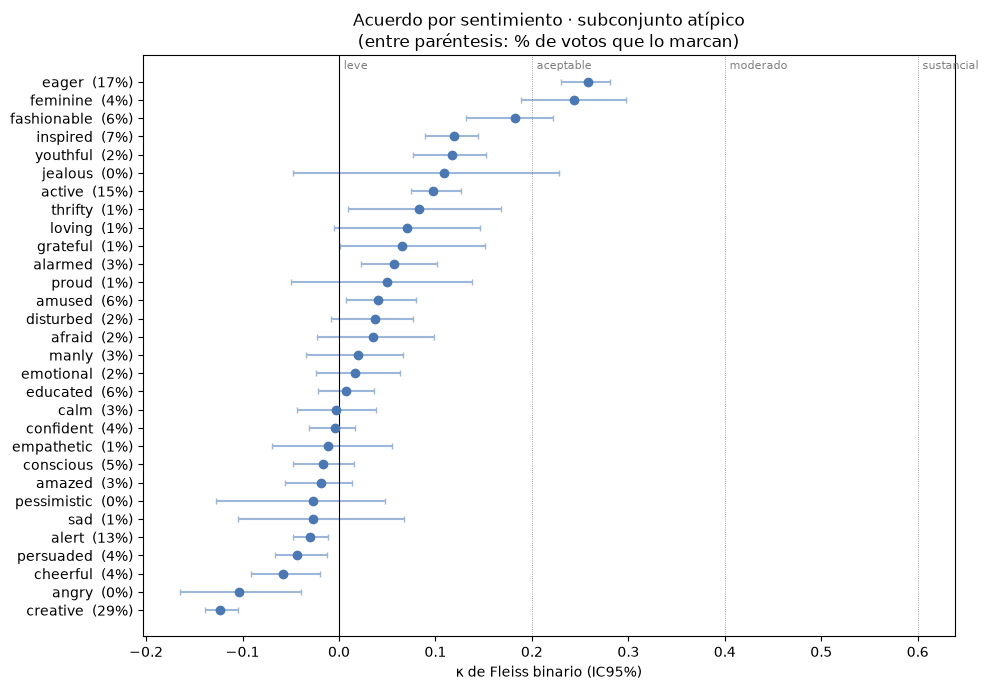

,sentimiento,prevalencia,κ,IC95_inf,IC95_sup,interpretación
0,eager,0.169,0.259,0.230,0.281,aceptable
1,feminine,0.038,0.243,0.189,0.297,aceptable
2,fashionable,0.063,0.183,0.132,0.222,leve
3,inspired,0.070,0.119,0.089,0.145,leve
4,youthful,0.022,0.117,0.076,0.152,leve
5,jealous,0.002,0.109,-0.048,0.228,leve
6,active,0.146,0.097,0.075,0.126,leve
7,thrifty,0.007,0.083,0.010,0.168,leve
8,loving,0.008,0.071,-0.005,0.146,leve
9,grateful,0.005,0.065,0.001,0.152,leve


In [9]:
def per_sentiment(ids, n_boot=100):
    rows = []
    for s in sorted(SENT_NAMES.values()):
        units = [[s in v for v in SENTS[k]] for k in ids]
        prev = np.mean([x for u in units for x in u])
        if prev == 0:
            continue
        k, lo, hi, *_ = fleiss(units, n_boot=n_boot)
        rows.append({'sentimiento': s, 'prevalencia': prev, 'κ': k, 'IC95_inf': lo, 'IC95_sup': hi})
    return pd.DataFrame(rows).sort_values('κ', ascending=False).reset_index(drop=True)

por_sent = per_sentiment(ATIP)
por_sent['interpretación'] = por_sent['κ'].map(landis_koch)
por_sent.to_csv(os.path.join(OUT, 'acuerdo_por_sentimiento.csv'), index=False)

fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(por_sent))[::-1]
ax.errorbar(por_sent['κ'], y, xerr=[por_sent['κ'] - por_sent['IC95_inf'], por_sent['IC95_sup'] - por_sent['κ']],
            fmt='o', color='#4a78b5', ecolor='#9db7da', capsize=2)
ax.set_yticks(y, [f"{s}  ({p:.0%})" for s, p in zip(por_sent['sentimiento'], por_sent['prevalencia'])])
for x, lab in [(0, 'leve'), (0.2, 'aceptable'), (0.4, 'moderado'), (0.6, 'sustancial')]:
    ax.axvline(x, color='grey', lw=0.6, ls=':')
    ax.text(x + 0.005, len(y) - 0.3, lab, fontsize=8, color='grey', ha='left')   # etiqueta = banda a la derecha
ax.axvline(0, color='black', lw=0.8)
ax.set(xlabel='κ de Fleiss binario (IC95%)', title='Acuerdo por sentimiento · subconjunto atípico\n(entre paréntesis: % de votos que lo marcan)')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'acuerdo_por_sentimiento.png'), dpi=150); plt.show()
por_sent

## 7. Acuerdo según la categoría atípica

¿Hay tipos de anuncio atípico en que los anotadores coinciden más? Una imagen puede estar en más de una categoría, así que los grupos se superponen.

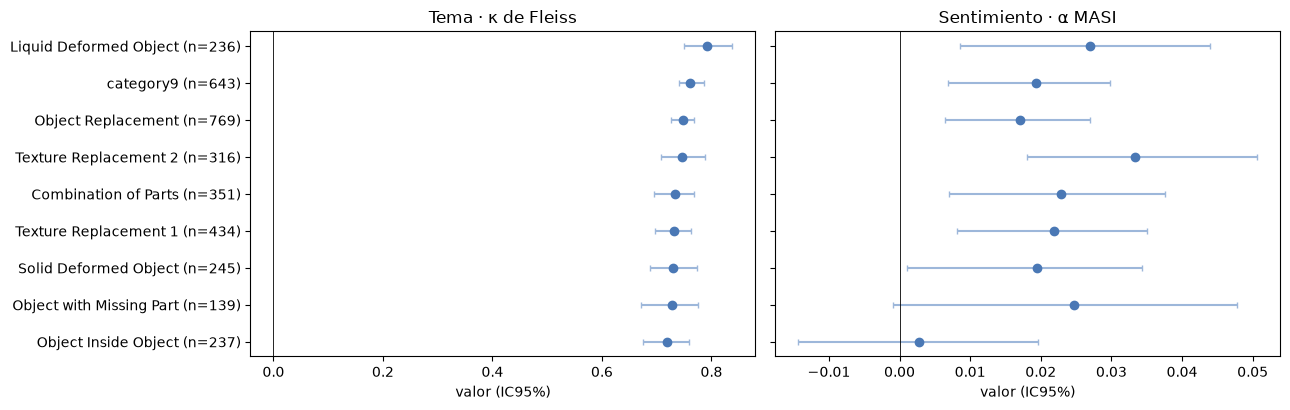

,categoría,imágenes,κ tema,κ tema inf,κ tema sup,α sentimiento MASI,α sent. inf,α sent. sup
0,Liquid Deformed Object,236,0.792,0.751,0.838,0.027,0.009,0.044
1,category9,643,0.760,0.740,0.787,0.019,0.007,0.030
2,Object Replacement,769,0.748,0.727,0.769,0.017,0.006,0.027
3,Texture Replacement 2,316,0.747,0.708,0.788,0.033,0.018,0.051
4,Combination of Parts,351,0.733,0.696,0.768,0.023,0.007,0.038
5,Texture Replacement 1,434,0.731,0.697,0.763,0.022,0.008,0.035
6,Solid Deformed Object,245,0.731,0.688,0.773,0.020,0.001,0.034
7,Object with Missing Part,139,0.727,0.671,0.775,0.025,-0.001,0.048
8,Object Inside Object,237,0.719,0.676,0.760,0.003,-0.014,0.020


In [10]:
rows = []
for cat in sorted(cts):
    ids = [k for k in ATIP if cat in site[k]['category']]
    kt, lt, ht, *_ = fleiss([TOPICS[k] for k in ids], n_boot=200)
    am, la, ha = krippendorff([SENTS[k] for k in ids], 'masi', n_boot=200)
    rows.append({'categoría': cat, 'imágenes': len(ids), 'κ tema': kt, 'κ tema inf': lt, 'κ tema sup': ht,
                 'α sentimiento MASI': am, 'α sent. inf': la, 'α sent. sup': ha})
por_cat = pd.DataFrame(rows).sort_values('κ tema', ascending=False).reset_index(drop=True)
por_cat.to_csv(os.path.join(OUT, 'acuerdo_por_categoria_atipica.csv'), index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
y = np.arange(len(por_cat))[::-1]
for ax, (col, lo, hi, title) in zip(axes, [('κ tema', 'κ tema inf', 'κ tema sup', 'Tema · κ de Fleiss'),
                                          ('α sentimiento MASI', 'α sent. inf', 'α sent. sup', 'Sentimiento · α MASI')]):
    ax.errorbar(por_cat[col], y, xerr=[por_cat[col] - por_cat[lo], por_cat[hi] - por_cat[col]],
                fmt='o', color='#4a78b5', ecolor='#9db7da', capsize=2)
    ax.set(title=title, xlabel='valor (IC95%)')
    ax.axvline(0, color='black', lw=0.6)
axes[0].set_yticks(y, [f'{c} (n={n})' for c, n in zip(por_cat['categoría'], por_cat['imágenes'])])
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'acuerdo_por_categoria_atipica.png'), dpi=150); plt.show()
por_cat

## 8. Resumen

In [11]:
res = pd.DataFrame(RESULTS)
res.to_csv(os.path.join(OUT, 'acuerdo_resumen.csv'), index=False)
res[['variable', 'conjunto', 'medida', 'valor', 'IC95_inf', 'IC95_sup', 'imágenes', 'interpretación']]

,variable,conjunto,medida,valor,IC95_inf,IC95_sup,imágenes,interpretación
0,tema,atípico,κ Fleiss,0.745,0.733,0.760,2404,sustancial
1,tema,atípico,α Krippendorff nominal,0.746,0.733,0.761,2404,tentativo
2,tema,completo,κ Fleiss,0.715,0.712,0.718,64340,sustancial
3,tema,completo,α Krippendorff nominal,0.717,0.714,0.720,64340,tentativo
4,sentimiento,atípico,κ Fleiss (conj. exacto),-0.001,-0.007,0.004,2404,pobre
5,sentimiento,atípico,α Krippendorff nominal,0.004,-0.002,0.009,2404,no confiable
6,sentimiento,atípico,α Krippendorff jaccard,0.031,0.025,0.037,2404,no confiable
7,sentimiento,atípico,α Krippendorff masi,0.021,0.015,0.027,2404,no confiable
8,sentimiento,completo,κ Fleiss (conj. exacto),0.021,0.019,0.023,30340,leve
9,sentimiento,completo,α Krippendorff nominal,0.023,0.021,0.025,30340,no confiable


## 9. Conclusiones

**Tema: acuerdo sustancial.** En el subconjunto atípico, κ de Fleiss = 0,745 y α nominal = 0,746. En el dataset completo los valores son casi iguales (0,715 y 0,717).
- El 86 % de los votos coincide con el tema más votado de su imagen, lo que reproduce el "85 % de acuerdo" del paper.
- El 64 % de las imágenes es unánime y el 7 % no tiene mayoría.
- El acuerdo no cambia con 3 o 5 anotadores, y es parecido en las 9 categorías atípicas: κ entre 0,72 y 0,80.
- Según Krippendorff, α ≈ 0,75 solo permite **conclusiones tentativas**: el tema es útil como etiqueta, pero no es un estándar de oro.

**Sentimiento: prácticamente sin acuerdo.** α MASI = 0,02 en el subconjunto atípico y 0,05 en el completo. κ como conjunto exacto ≈ 0.
- El crédito parcial (Jaccard o MASI) casi no lo cambia, así que el problema no es la forma de comparar conjuntos: los anotadores **eligen sentimientos distintos**.
- Por sentimiento, el máximo es κ ≈ 0,26 (*eager*, *feminine*): un acuerdo apenas aceptable.
- *creative*, el sentimiento más marcado (29 % de los votos), tiene κ **negativo** (−0,12). En la mayoría de las imágenes lo marca exactamente un anotador, con más frecuencia de la que daría el azar. Parece una opción "comodín" para anuncios atípicos, no una respuesta a cada imagen en particular.
- El paper no informa el acuerdo en sentimientos. Estos resultados indican que las etiquetas de sentimiento de este dataset **no deberían usarse como verdad de referencia** sin agregarlas o modelar a cada anotador.

**Qué muestra el sitio (notebook 06):** en sentimientos muestra la **unión** de lo que marcaron todos los anotadores en el 100 % de las imágenes, no la mayoría. En temas, coincide con la unión en el 92 % de las imágenes y con la mayoría en solo el 65 %. Por eso una imagen puede aparecer allí con 5 a 10 sentimientos aunque cada anotador marcó en promedio 1,4.

Resultados guardados en `resultados/pitt/`: `acuerdo_resumen.csv`, `acuerdo_por_sentimiento.csv`, `acuerdo_por_categoria_atipica.csv` y las figuras `.png`.